# Walkthrough 2: positions, probability and risk

Walkthrough 1 priced **one** option. This one builds everything the tool shows for a **whole position**:

| Module | What it does |
|---|---|
| `position.py` | legs, entry cost, value, profit, break-evens, maximum profit and loss, net Greeks |
| `probability.py` | where the price may finish, and the chance of profit |
| `scenarios.py` | the scenario grid and the P/L explain a risk desk reports |
| `work.py` | every intermediate value, for the tool's "show your work" panel |

Read it with the source files open. Each section gives the idea, the formula, the code, and a check that the code is right. When you finish, do `exercises/risk.py`: the tests in `exercises/test_risk.py` compare your functions with the engine.

**Running example.** A bull call spread on a stock at 166: buy 10 calls struck at 170, sell 10 calls struck at 190, both 30 days out. The higher strike trades at a lower implied volatility (60% against 64%), as equity skew usually has it.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import ndtr

import quantcore as qc
from quantcore import black_scholes as bs
from quantcore import probability, scenarios
from quantcore.work import show_work

spread = qc.Position(
    spot=166.0,
    rate=0.04,
    legs=[
        qc.Leg("call", 10, strike=170, days=30, vol=0.64),
        qc.Leg("call", -10, strike=190, days=30, vol=0.60),
    ],
)
spread

Position(spot=166.0, legs=(Leg(kind='call', quantity=10, strike=170, days=30, vol=0.64, multiplier=100.0, entry_price=None), Leg(kind='call', quantity=-10, strike=190, days=30, vol=0.6, multiplier=100.0, entry_price=None)), rate=0.04, div_yield=0.0, exercise='european', tree_steps=201)

## 1. A position is a list of legs

Each leg is a call, a put or the stock, held long (positive quantity) or short (negative). One option contract controls 100 shares, so the leg's **size** in shares is

$$\text{size} = \text{quantity} \times 100 \quad\text{(options)},\qquad \text{size} = \text{quantity}\quad\text{(stock)}.$$

Everything in money is size times a price per share. The sign convention, used everywhere:

| Quantity | Positive means | Negative means |
|---|---|---|
| `entry_cost` | you paid (net debit) | you received (net credit) |
| `profit` | you made money | you lost money |

$$\text{entry cost} = \sum_i \text{size}_i \times \text{entry price}_i, \qquad \text{profit}(S, t) = \text{value}(S, t) - \text{entry cost}.$$

The entry price is what you typed, or, if you left it empty, the model price today. So an untouched position starts at exactly zero profit.

In [2]:
for leg in spread.legs:
    price = qc.entry_price(leg, spread)
    print(f"{leg.kind:>4} size {leg.size:>+7.0f}  x  {price:7.4f}  =  {leg.size * price:>+10.2f}")
print(f"{'entry cost':>40} = {qc.entry_cost(spread):>+10.2f}   (positive: a net debit)")
print("profit at today's price, today:", round(float(qc.profit(spread, spread.spot)), 10))

call size   +1000  x  10.6152  =   +10615.17
call size   -1000  x   3.8832  =    -3883.22
                              entry cost =   +6731.95   (positive: a net debit)
profit at today's price, today: 0.0


## 2. Value, profit and the expiry curve

`value(position, prices, days_forward, vol_scale, vol_shift)` prices every leg at the given underlying prices, a number of days from today, with volatility scaled and shifted, and adds them up. It broadcasts, so one call prices a whole axis.

The model only runs to the **first expiry** in the position. After that, an expired leg has settled into cash and no longer moves with the price.

**Break-evens** are the prices where profit at expiry is zero. The payoff at expiry is piecewise linear, so there is no single formula for every position. The engine scans 4,001 prices on a wide geometric grid, finds each change of sign, and refines it with Brent's method (`scipy.optimize.brentq`), which is guaranteed to converge once a root is bracketed.

**Maximum profit and loss** come from the same kind of scan. To decide whether either is unlimited, the engine looks at the slope of the profit far above the highest strike: only calls and stock still move up there.

break-evens: [176.73]
max profit 13,268.05   max loss -6,731.95


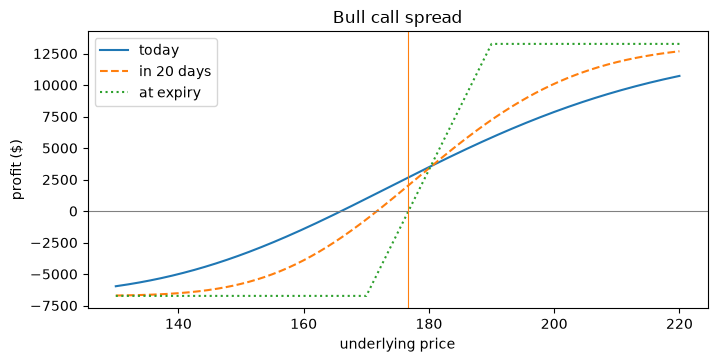

In [3]:
prices = np.linspace(130, 220, 361)
evens = qc.breakevens(spread)
best, worst = qc.profit_range(spread)
print("break-evens:", [round(x, 2) for x in evens])
print(f"max profit {best:,.2f}   max loss {worst:,.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
for days, style in ((0, "-"), (20, "--"), (30, ":")):
    label = "today" if days == 0 else ("at expiry" if days == 30 else f"in {days} days")
    ax.plot(prices, qc.profit(spread, prices, days), style, label=label)
ax.axhline(0, color="grey", lw=0.8)
for x in evens:
    ax.axvline(x, color="tab:orange", lw=0.8)
ax.set_xlabel("underlying price"); ax.set_ylabel("profit ($)"); ax.legend(); ax.set_title("Bull call spread")
plt.show()

Check the expiry numbers by hand. At expiry a 170/190 call spread pays $\max(S-170,0)-\max(S-190,0)$ per share: nothing below 170, rising one for one up to 20 at 190 and above. On 1,000 shares that is at most \$20,000, so

- max profit $= 20{,}000 - \text{entry cost}$,
- max loss $= -\text{entry cost}$,
- break-even $= 170 + \text{entry cost}/1{,}000$.

In [4]:
cost = qc.entry_cost(spread)
print("max profit:", round(20_000 - cost, 2), "  engine:", round(best, 2))
print("max loss:  ", round(-cost, 2), "  engine:", round(worst, 2))
print("break-even:", round(170 + cost / 1000, 4), "  engine:", round(evens[0], 4))

max profit: 13268.05   engine: 13268.05
max loss:   -6731.95   engine: -6731.95
break-even: 176.7319   engine: 176.7319


## 3. Net Greeks: just add them up

A position's value is a sum over legs, and differentiation is linear, so every Greek of the position is the sum of each leg's Greek times its size:

$$\Delta_{\text{position}} = \sum_i \text{size}_i\, \Delta_i \qquad\text{(and the same for } \Gamma, \Theta, \text{vega)}.$$

`net_greeks` reports them in money terms: delta in share-equivalents, theta per calendar day, vega per volatility point. Check them the same way Walkthrough 1 checked single options: bump the input, reprice the whole position, and compare.

In [5]:
g = {k: float(v) for k, v in qc.net_greeks(spread).items()}
S, h = spread.spot, 0.01
bumped = {
    "delta": (qc.value(spread, S + h) - qc.value(spread, S - h)) / (2 * h),
    "gamma": (qc.value(spread, S + h) - 2 * qc.value(spread, S) + qc.value(spread, S - h)) / h**2,
    "theta_per_day": (qc.value(spread, S, days_forward=1e-3) - qc.value(spread, S)) / 1e-3,
    "vega_per_point": (qc.value(spread, S, vol_shift=0.0005) - qc.value(spread, S, vol_shift=-0.0005)) / 0.1,
}
for name in g:
    print(f"{name:>15}: formula {g[name]:>11.4f}   bump and reprice {float(bumped[name]):>11.4f}")

          delta: formula    243.6958   bump and reprice    243.6958
          gamma: formula      2.0074   bump and reprice      2.0074
  theta_per_day: formula    -55.4931   bump and reprice    -55.4943
 vega_per_point: formula     39.1428   bump and reprice     39.1428


Now look at the signs, and how they change with the price. At 166 the position sits just below the long 170 strike, so the long call dominates: long delta, long gamma, long vega. Move the price up to 195, past the short 190 strike, and the short call takes over.

In [6]:
for s in (166.0, 195.0):
    g_at = {k: float(v) for k, v in qc.net_greeks(spread, s).items()}
    print(f"at {s:.0f}: " + "   ".join(f"{k} {v:>+9.2f}" for k, v in g_at.items()))

at 166: delta   +243.70   gamma     +2.01   theta_per_day    -55.49   vega_per_point    +39.14
at 195: delta   +203.32   gamma     -3.79   theta_per_day    +48.26   vega_per_point    -61.41


Above the upper strike the spread is short gamma and short vega and earns time decay: it has nearly reached its maximum payoff, so any extra movement or volatility can only take value away. A spread is a bet on direction with its upside capped, and its volatility exposure flips sign across the strikes.

## 4. Where the price might finish

Black-Scholes assumes the log of the price at a future date is normal:

$$\ln S_T \sim \mathcal N\!\Big(\ln S + \big(\mu - q - \tfrac12\sigma^2\big)T,\; \sigma^2 T\Big).$$

- With $\mu = r$ this is the **risk-neutral** distribution: the one under which option prices are fair. Its mean is the forward price, $\mathbb E[S_T] = S e^{(r-q)T}$.
- With $\mu$ set to your own expected return, it is a **real-world** view.

The $-\tfrac12\sigma^2$ is the convexity correction: because $e^x$ is convex, a log-price centred at $\ln S + \mu T$ would give a mean price above $S e^{\mu T}$. Subtracting $\tfrac12\sigma^2 T$ makes the mean of the price come out right.

density integrates to: 1.0
mean of S_T:           166.5467
forward S e^(rT):      166.5467


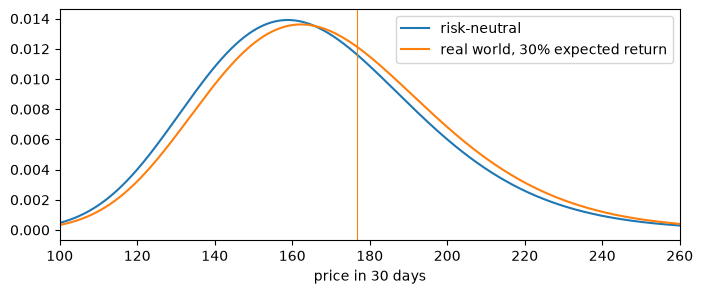

In [7]:
days, vol = 30, 0.62
grid = np.linspace(20, 800, 80001)  # wide enough to hold all but a sliver of the probability
pdf = probability.density(grid, spread.spot, days, vol, spread.rate)
print("density integrates to:", round(float(np.trapezoid(pdf, grid)), 6))
print("mean of S_T:          ", round(float(np.trapezoid(grid * pdf, grid)), 4))
print("forward S e^(rT):     ", round(spread.spot * math.exp(spread.rate * days / 365), 4))

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(grid, pdf, label="risk-neutral")
ax.plot(grid, probability.density(grid, spread.spot, days, vol, spread.rate, drift=0.30), label="real world, 30% expected return")
for x in qc.breakevens(spread):
    ax.axvline(x, color="tab:orange", lw=0.8)
ax.set_xlim(100, 260); ax.set_xlabel("price in 30 days"); ax.legend(); plt.show()

## 5. Chance of profit

Cut the price axis at the break-evens. In each stretch the position either makes money at expiry or loses it, everywhere in the stretch. So the chance of profit is the probability of finishing in the profitable stretches:

$$P(a < S_T < b) = N\!\left(\frac{\ln b - m}{s}\right) - N\!\left(\frac{\ln a - m}{s}\right), \qquad m = \mathbb E[\ln S_T],\; s = \sigma\sqrt T.$$

**One volatility for several legs.** The legs here have different volatilities, but the distribution needs one $\sigma$. The engine weights each leg's volatility by how much the position depends on it:

$$\bar\sigma = \frac{\sum_i w_i \sigma_i}{\sum_i w_i}, \qquad w_i = |\text{size}_i| \times \text{vega}_i.$$

This is an approximation, and section 6 shows what it costs.

In [8]:
print("weights (leg, vol, |size| x vega):", [(i, v, round(w, 1)) for i, v, w in probability.vol_weights(spread)])
vol_bar = probability.representative_vol(spread)
print("representative vol:", round(vol_bar, 4))

for piece in probability.outcome_intervals(spread):
    high = "inf" if math.isinf(piece.high) else f"{piece.high:.2f}"
    print(f"{piece.low:>8.2f} to {high:>6}: {'profit' if piece.profitable else 'loss  '}  probability {piece.probability:.4f}")
print("chance of profit:", round(probability.chance_of_profit(spread), 4))

weights (leg, vol, |size| x vega): [(0, 0.64, 18982.1), (1, 0.6, 15067.8)]
representative vol: 0.6223
    0.00 to 176.73: loss    probability 0.6635
  176.73 to    inf: profit  probability 0.3365
chance of profit: 0.3365


Check it by simulation: draw two million finishing prices from the same lognormal distribution, compute the expiry profit of each, and count how often it is positive.

In [9]:
rng = np.random.default_rng(7)
T = 30 / 365
z = rng.standard_normal(2_000_000)
finish = spread.spot * np.exp((spread.rate - 0.5 * vol_bar**2) * T + vol_bar * math.sqrt(T) * z)
hits = qc.profit_at_expiry(spread, finish) > 0
p, se = hits.mean(), hits.std() / math.sqrt(len(hits))
print(f"simulated {p:.4f} +/- {1.96 * se:.4f}   formula {probability.chance_of_profit(spread):.4f}")
print("with a 30% expected return:", round(probability.chance_of_profit(spread, drift=0.30), 4))

simulated 0.3362 +/- 0.0007   formula 0.3365
with a 30% expected return: 0.3813


**Risk-neutral is not a forecast.** The headline number assumes the stock grows at the 4% interest rate. Someone who expects 30% a year sees a higher chance for this bullish spread. Brokers quote the risk-neutral number, and it is easy to misread it as a prediction.

## 6. A self-check: options earn the interest rate, on average

Under the risk-neutral distribution every fairly priced asset grows, on average, at the risk-free rate. So if every leg were priced at **one** volatility and the chance of profit used that same volatility, the average profit at expiry would be exactly the financing cost:

$$\mathbb E^{\mathbb Q}[\text{profit}_T] = \text{entry cost}\times\big(e^{rT}-1\big).$$

`expected_profit` integrates profit times density over 8,001 points, eight standard deviations each side, so this is a real test of the numerics. With the skewed legs the identity breaks, because one representative volatility cannot price both legs at once. That gap is the cost of the approximation.

In [10]:
flat = qc.Position(spot=166.0, rate=0.04, legs=[qc.Leg("call", 10, strike=170, days=30, vol=0.62), qc.Leg("call", -10, strike=190, days=30, vol=0.62)])
for name, pos in (("flat 62% on both legs", flat), ("skewed 64% / 60%", spread)):
    c = qc.entry_cost(pos)
    print(f"{name:>22}: average profit {probability.expected_profit(pos):>8.2f}   financing cost {c * (math.exp(0.04 * 30 / 365) - 1):>8.2f}")

 flat 62% on both legs: average profit    19.92   financing cost    19.92
      skewed 64% / 60%: average profit  -655.54   financing cost    22.17


The skewed spread shows an average profit of about −\$656: this is the number the tool's risk panel shows for this position. It is not a sign that the spread is mispriced. The long call was bought at 64% volatility and the short call sold at 60%, but the distribution uses one blended 62.2%. Under that single distribution the long call you bought looks overpriced and the short call you sold looks underpriced, so both legs lose on average. If an interviewer asks why "fairly priced" options show an expected loss, this is the answer: skew.

## 7. The scenario grid

A payoff chart shows one volatility. A risk desk asks a different question: *what do I lose if the price drops 10% and volatility jumps 10 points at the same time?* The scenario grid answers it by **full repricing**, not by Greeks, for every pair of a price shock and a volatility shift:

$$\text{profit}\big(S(1+\text{shock}),\; \sigma_i + \text{shift}\big)\quad\text{for every leg } i.$$

The shift is additive (+10 points on every leg), the way desks quote volatility shocks. It is a **parallel** shift: the skew keeps its shape.

In [11]:
table = scenarios.scenario_grid(spread)
print("vol \\ price " + "".join(f"{s:>+8.0%}" for s in table.price_shocks))
for shift, row in zip(table.vol_shifts[::-1], table.profit[::-1]):
    print(f"{shift * 100:>+7.0f} pts  " + "".join(f"{v:>8,.0f}" for v in row))

vol \ price     -20%    -15%    -10%     -5%     +0%     +5%    +10%    +15%    +20%
    +20 pts    -4,754  -3,714  -2,445  -1,000     556   2,150   3,715   5,195   6,550
    +10 pts    -5,247  -4,253  -2,954  -1,400     328   2,129   3,907   5,577   7,082
     +0 pts    -5,750  -4,863  -3,581  -1,929       0   2,066   4,121   6,035   7,719
    -10 pts    -6,208  -5,515  -4,336  -2,629    -474   1,937   4,368   6,603   8,499
    -20 pts    -6,545  -6,125  -5,192  -3,545  -1,171   1,698   4,667   7,342   9,475


Read across the volatility rows, one column at a time:

- **At today's price** (0%), more volatility helps a little: the spread is long vega there, as section 3 showed.
- **In a rally** (+20%), more volatility *hurts*: the price is past the short 190 strike, where the spread is short vega.
- **In a sell-off** (−20%), more volatility helps: it keeps alive the chance of recovering above 170 before expiry. Whatever happens, the loss can never exceed the \$6,732 paid.

One table shows that the position's volatility exposure changes sign with the price. A single vega number cannot.

## 8. P/L explain

A risk report splits each day's profit into the parts the Greeks predict. Expand the value in a Taylor series around today:

$$\Delta V \approx \Delta\cdot\delta S + \tfrac12\Gamma\cdot\delta S^2 + \Theta\cdot\delta t + \text{vega}\cdot\delta\sigma.$$

The Greeks are measured **before** the move, as a morning risk report would be. The exact change comes from repricing after the move, and the difference is **unexplained**: the higher-order terms (third derivative in price, cross terms such as vanna and charm) that a second-order expansion leaves out.

In [12]:
e = scenarios.explain(spread, price_move=0.05 * spread.spot, days_passed=7, vol_shift=0.02)
for name in ("delta", "gamma", "theta", "vega"):
    print(f"{name:>12}: {getattr(e, name):>+10.2f}")
print(f"{'predicted':>12}: {e.predicted:>+10.2f}")
print(f"{'actual':>12}: {e.actual:>+10.2f}")
print(f"{'unexplained':>12}: {e.unexplained:>+10.2f}")

       delta:   +2022.67
       gamma:     +69.14
       theta:    -388.45
        vega:     +78.29
   predicted:   +1781.65
      actual:   +1876.27
 unexplained:     +94.61


How big is the unexplained part? For a pure price move the expansion stops at the square, so what is left is dominated by the cubic term and should grow roughly like $\delta S^3$. Doubling the move should multiply the error by about eight, until the move is so large that the expansion stops being useful at all.

move    1: unexplained      -0.04
move    2: unexplained      -0.36
move    4: unexplained      -2.87
move    8: unexplained     -22.92
move   16: unexplained    -180.56
move   32: unexplained   -1334.38
ratios when the move doubles: [8.01 8.01 8.   7.88 7.39]


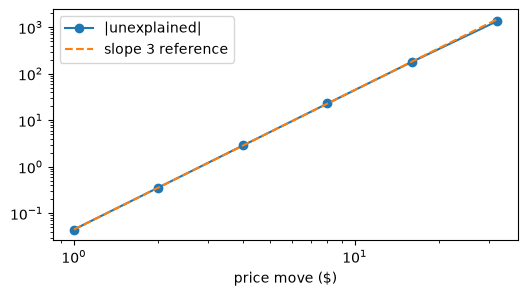

In [13]:
moves = np.array([1, 2, 4, 8, 16, 32], dtype=float)
left = np.array([scenarios.explain(spread, m).unexplained for m in moves])
for m, u in zip(moves, left):
    print(f"move {m:>4.0f}: unexplained {u:>+10.2f}")
print("ratios when the move doubles:", np.round(left[1:] / left[:-1], 2))

fig, ax = plt.subplots(figsize=(6, 3))
ax.loglog(moves, np.abs(left), "o-", label="|unexplained|")
ax.loglog(moves, np.abs(left[0]) * moves**3, "--", label="slope 3 reference")
ax.set_xlabel("price move ($)"); ax.legend(); plt.show()

The rule this teaches: **Greeks describe small moves.** For a big move, look at the scenario grid, which reprices fully.

## 9. Show your work

`work.show_work(position)` keeps the intermediate values that the functions above normally throw away: $T$, $d_1$, $d_2$, $N(d_1)$, $N(d_2)$, the discount factors, each leg's price, cost and Greeks, the volatility weights, the log-price moments and the probability of each stretch. The tool's "show your work" panel prints exactly these, substituted into each formula. The tests in `tests/test_work.py` check that the pieces rebuild the engine's own numbers.

In [14]:
w = show_work(spread)
leg = w.legs[0]
print(f"leg 1: T={leg.years:.4f}  d1={leg.d1:.4f}  d2={leg.d2:.4f}  N(d1)={leg.n_d1:.4f}  N(d2)={leg.n_d2:.4f}")
rebuilt = spread.spot * leg.spot_discount * leg.n_d1 - leg.strike * leg.strike_discount * leg.n_d2
print(f"S e^-qT N(d1) - K e^-rT N(d2) = {rebuilt:.6f}   price {leg.european_price:.6f}")
print("leg costs:", [round(l.cost, 2) for l in w.legs], " sum", round(sum(l.cost for l in w.legs), 2), " entry cost", round(w.entry_cost, 2))
print("chance:", round(w.chance.chance, 4), " from", len(w.chance.intervals), "stretches")

leg 1: T=0.0822  d1=-0.0201  d2=-0.2036  N(d1)=0.4920  N(d2)=0.4193
S e^-qT N(d1) - K e^-rT N(d2) = 10.615171   price 10.615171
leg costs: [10615.17, -3883.22]  sum 6731.95  entry cost 6731.95
chance: 0.3365  from 2 stretches


## 10. How we know it is right

- `tests/test_position.py`: entry cost and profit for standard strategies, break-evens and limits against hand calculations, unlimited profit and loss detected, Greeks against bump-and-reprice.
- `tests/test_probability.py`: the density integrates to one with the forward as its mean, the CDF equals the textbook $N(d_2)$, chance of profit for a long call and an iron condor in closed form and against simulation, and the risk-neutral average profit equals the financing cost.
- `tests/test_scenarios.py`: the grid matches direct repricing, the explain adds up, and the unexplained part shrinks for small moves.
- `tests/test_work.py`: every intermediate value rebuilds the headline numbers.

## 11. Where this is wrong

The main limits, all listed with examples on the tool's [model limits page](https://options.blessedshoh.dev/limits):

1. **One representative volatility** for the chance of profit, which section 6 showed breaking a clean identity.
2. **Lognormal tails** are too thin, so the chance of profit is too optimistic for positions that lose in a crash or a gap.
3. **Parallel volatility shocks** in the scenario grid: real sell-offs steepen the skew.
4. **Greeks are local**: the P/L explain's unexplained part grows like the cube of the move.

## 12. Before the exercises: check yourself

Answer out loud, without code:

1. Why is the chance of profit computed by cutting at the break-evens, rather than with one $N(d_2)$?
2. What does the $-\tfrac12\sigma^2$ in the mean of $\ln S_T$ do, and what would go wrong without it?
3. Why might a position with positive delta still lose money when the price rises?
4. In the P/L explain, why should the unexplained part grow roughly like the cube of the move?
5. A broker shows an 80% chance of profit on a short strangle. What two things would you check before believing that it is a good trade?

Then open `exercises/risk.py`.